# Video lock: steadier answers on a live clip

In Milestone 3 the app shows a species when 4 of the last 6 frames agree on it, and how sure each
frame is never counts. On a real clip where Russell's viper sat near 62%, the shown answer changed
13 times. The new rule pools each frame's outputs over the last few frames with a snake (the window, 5 or 10, is tuned below):

- it pools every output the verdict rules read (species, WHO, genus and family probabilities and the
  embedding), shows "Checking..." until the pooled top species holds the confidence threshold and leads the
  runner-up by `margin`, then it **locks** on that species;
- a locked answer switches only when another species clearly leads for a full second;
- "dangerous" may show while checking; "not on the WHO list" and "we don't know" only after the lock.

This notebook runs both rules on the same clips with the model the app ships in Milestone 4, A3 (the
crop to the predicted mask's box, front end F1m), behind the app's Milestone 4 front end: the exposure
fix, the M4 detector and segmenter, the no-snake gate (rule and cut-offs from `results/m4/gate/gate.json`;
a frame that fails it has no snake), then A3's crop. Every threshold the verdict rules use, the
confidence threshold included, is A3's own (`decision_metrics.json`). Before the clips it measures how
far A3's validation top-1 moves when the M4 front end cuts its input instead of the M3 front end it was
trained and scored with. It tunes `window` and `margin` on dev clips only (synthetic clips
from validation photos plus real dev clips), then scores the test clips once
with the chosen pair (the Milestone 3 model's run scored its test clips three times while the
method was being fixed; section 7 says how). The real clips are
Wikimedia Commons videos under CC BY, CC BY-SA, CC0 or public domain; the species comes from the file
page (`species_source` in `clips.csv`: `stated` in the text, `category` only in the file's category, or
`inferred` where the page names only the genus or "cobra"); species correctness is scored only on
`stated` and `category` clips. Their credits are in `clips.csv` and the clips folder. The same notebook
on the Milestone 3 model is kept as `results/m4/video/executed/24_video_lock_M3.ipynb`, with its results
in `results/m4/video/M3/`. No paid calls: everything runs on the laptop's CPU.

In [1]:
import hashlib, json, os, sys, urllib.request, warnings
from pathlib import Path

os.environ.update(YOLO_VERBOSE="False", YOLO_OFFLINE="1", NO_ALBUMENTATIONS_UPDATE="1")
warnings.filterwarnings("ignore")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

sys.path.insert(0, "../src")
from serpentguard import decide, front_end, metrics, video
from serpentguard.data import AUGMENT, apply_mode, clean_mask, fix_exposure, input_mode, load_rgb
from serpentguard.models import build_model

WORK = Path("../..")  # the folder beside the repo
RUN = os.environ.get("RUN", "A3")  # the full run; its results go to results/m4/video/<RUN>
MODEL_DIR = Path(os.environ.get("MODEL_DIR", WORK / "m3-video-demo/models_A3"))  # best.pt, prototypes.npz, decision_metrics.json, val_outputs.npz, detector.pt, segmenter.pt
CLIPS_DIR = Path(os.environ.get("CLIPS_DIR", WORK / "m4-video-clips"))  # real clips and CREDITS.md, never committed
METADATA = Path(os.environ.get("METADATA", WORK / "kaggle/clean_build/out/metadata.csv"))
M3_SEGMENTER_DIR = Path(os.environ.get("M3_SEGMENTER_DIR", WORK / "kaggle/m4_runs/frontend_full/weights_ds/dl/frontends/S1/unet"))
M3_UNET_SHA256 = "f7646444ec409614e992cd7a112a1c2c47fd81a1dc62afea54f50f83664abf3f"  # notebook 21's check
RESULTS_M4 = Path("../results/m4")
VIDEO = RESULTS_M4 / "video"  # clips.csv and negatives.csv: the clip lists, the same for every model
RESULTS = VIDEO / RUN
GATE_FILE = RESULTS_M4 / "gate/gate.json"
RUN_FOLDER = RESULTS_M4 / "full" / RUN  # the run's decision_metrics.json and the sha256 of its files
SEGMENTER_KIND = "unet"
MARGINS = (0.05, 0.1, 0.15, 0.2, 0.3)
WINDOWS = (5, 10)  # frames pooled; tuned with the margin
MAX_CHANGES, MAX_FIRST_ANSWER = 1, 3.0  # the tuning rule: median changes, median seconds to first answer
G5_MAX_CHANGES = 1  # G5: the shown species changes at most once per clip after the first answer
N_SYNTHETIC, SEED = 20, 42
N_LISTED_PER_SPECIES = 2  # synthetic clips per WHO-listed species with CC0 or CC BY validation photos
SYNTH_LICENCES = ("cc0", "cc-by")
N_SHIFT, SHIFT_SEED = 300, 42  # validation photos of the front-end shift check
SHIFT_TOLERANCE = 0.02  # a top-1 more than this far below the saved one is a concern
MAX_CLIP_SECONDS = 30  # of a real clip
INFER_LATENCY = 0.1  # the phone reads at most 10 frames a second
BATCH = 16  # photos per front-end and model call
CACHE = CLIPS_DIR / "cache"
PHOTOS = CLIPS_DIR / "val_photos"
for folder in (RESULTS, CACHE, PHOTOS):
    folder.mkdir(parents=True, exist_ok=True)
print("model folder:", MODEL_DIR.name, "; results:", RESULTS)

model folder: models_A3 ; results: ../results/m4/video/A3


## 1. The model, the front end and the verdict rules

The model files must be the shipped run's (their sha256 is in the run's `manifest.json`), and its
`decision_metrics.json` must be the one in the repo.

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


checkpoint = torch.load(MODEL_DIR / "best.pt", map_location="cpu", weights_only=True)
cfg = checkpoint["config"]
model = build_model(cfg, pretrained=False)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
shipped = json.loads((RUN_FOLDER / "manifest.json").read_text())["not_in_repo"]
for name in ("best.pt", "prototypes.npz", "val_outputs.npz"):
    assert sha256(MODEL_DIR / name) == shipped[f"{cfg['run_id']}/{name}"]["sha256"], f"{name} is not run {RUN}'s"
assert (MODEL_DIR / "decision_metrics.json").read_bytes() == (RUN_FOLDER / "decision_metrics.json").read_bytes()
MODE = input_mode(cfg)
assert MODE == "mask_box_crop" and cfg["mask_source"] == "predicted", "this notebook cuts A3's crop from the segmenter's mask"
decision = json.loads((MODEL_DIR / "decision_metrics.json").read_text())
thresholds = decide.Thresholds(**decision["thresholds"])
SCORER, SCALE = decision["scorer"], cfg.get("arcface_s")
with np.load(MODEL_DIR / "prototypes.npz") as saved:
    prototypes = saved[decision["prototype_set"]]
tables = decide.repo_tables()
classes = pd.read_csv("../data/classes.csv")
class_id = dict(zip(classes["species"], classes["class_id"]))
NAMES = classes.set_index("class_id")["species"]
detector = YOLO(str(MODEL_DIR / "detector.pt"))
segmenter = front_end.Segmenter(SEGMENTER_KIND, MODEL_DIR)
gate = json.loads(GATE_FILE.read_text())
KEYS = ["embedding", "species_logits", "who_logits", "genus_logits", "family_logits"]
CONF = thresholds.theta_conf
front_files = {name: sha256(MODEL_DIR / name) for name in ("best.pt", "detector.pt", "segmenter.pt")}
MODEL_TAG = RUN + "_" + hashlib.sha256(json.dumps([front_files, gate["rule"], gate["thresholds"]]).encode()).hexdigest()[:12]
print(f"model {cfg['run_id']} (run {RUN}, front end {cfg['front_end']} = {MODE}, {cfg['mask_source']} masks, {SCORER} scorer)")
print("verdict thresholds from its decision_metrics.json:", {k: round(v, 4) for k, v in decision["thresholds"].items()})
print(f"gate: rule {gate['rule']!r}, cut-offs {gate['thresholds']} ({GATE_FILE.name}); "
      f"detector {front_files['detector.pt'][:12]}, segmenter {front_files['segmenter.pt'][:12]}; cache tag {MODEL_TAG}")

model M4_FULL (run A3, front end F1m = mask_box_crop, predicted masks, head scorer)
verdict thresholds from its decision_metrics.json: {'temperature': 1.8064, 'temperature_who': 0.9002, 'theta_d': 0.0844, 'theta_who': 0.1389, 'tau_unknown': 0.6049, 'theta_conf': 0.2893, 'theta_v': 0.5, 'theta_genus': 0.5}
gate: rule 'both', cut-offs {'box_conf': 0.00499307457357645, 'mask_area': 4.8e-05} (gate.json); detector 29a1ad1c1b9b, segmenter b881c338356b; cache tag A3_adb6a1abdbc0


## 2. One frame through the app's path

The app's steps on each frame: the exposure fix; the M4 detector and segmenter (`front_end.gate_parts`, the
code that scored the gate's photos); the gate (`front_end.gate_calls` with the rule and cut-offs of
`gate.json`; a frame that fails it is `None`, no snake); then A3's input, cut by the functions training
used for F1m: `clean_mask` (as `load_mask` cleans a saved mask) and `apply_mode` in `mask_box_crop` mode,
the crop to the mask's box. A mask that cleaning drops gives the whole frame, as in training. Then the
model: the frame's temperature-scaled species, WHO, genus and family probabilities and its embedding come
out, and the lock pools all of them, so the verdict rules see the same signals as for one photo. The
detector and the segmenter do both the gate and the crop, so the app runs one front end; A3 itself was
trained and scored on crops cut from M3's U-Net masks, which section 3 measures.

In [3]:
def a3_inputs(rgbs, masks):
    """A3's letterboxed inputs, the crop to each cleaned mask's box, and which photos are left whole because
    cleaning left no mask (training gave those the whole photo too)."""
    cleaned = [clean_mask(mask) for mask in masks]
    inputs = [apply_mode(rgb, mask, MODE, None, cfg["input_size"])[0] for rgb, mask in zip(rgbs, cleaned)]
    return inputs, [mask is None for mask in cleaned]


def app_front_end(rgbs):
    """Per exposure-fixed photo: the gate's scores, whether the gate calls it a snake, and A3's input."""
    parts = []
    for start in range(0, len(rgbs), BATCH):
        parts += front_end.gate_parts(rgbs[start:start + BATCH], detector, segmenter)
    scores = pd.DataFrame({"box_conf": [p["box_conf"] for p in parts], "mask_area": [p["mask_area"] for p in parts]})
    called = front_end.gate_calls(scores, gate["rule"], gate["thresholds"])
    inputs, whole = a3_inputs(rgbs, [p["mask"] for p in parts])
    return scores.assign(passed=called, whole_photo=whole), inputs


def model_outputs(inputs):
    outputs = {key: [] for key in KEYS}
    for start in range(0, len(inputs), BATCH):
        images = torch.stack([AUGMENT["eval"](image=x)["image"] for x in inputs[start:start + BATCH]])
        with torch.inference_mode():
            out = model(images)
        for key in KEYS:
            outputs[key].append(out[key].float().numpy())
    return {key: np.concatenate(values) for key, values in outputs.items()}


def pool_items(outputs):
    """Each photo's parts for the pool: temperature-scaled probabilities of every head, and the embedding."""
    found = decide.signals(outputs, thresholds.temperature, thresholds.temperature_who, prototypes,
                           tables, SCORER, SCALE)

    def row(head, i):
        return None if head is None else head[i]

    return [{"probs": found.probs[i], "who": row(found.who_head, i), "genus": row(found.genus_head, i),
             "family": row(found.family_head, i), "embedding": outputs["embedding"][i]}
            for i in range(len(found.probs))]


def frames_outputs(frames):
    """Per frame: its parts for the pool, or None when the gate finds no snake; and the gate's scores."""
    gate_table, inputs = app_front_end([fix_exposure(f) for f in frames])
    items = [None] * len(frames)
    kept = np.flatnonzero(gate_table["passed"].to_numpy())
    if len(kept):
        for i, item in zip(kept, pool_items(model_outputs([inputs[i] for i in kept]))):
            items[i] = item
    return items, gate_table


def read_video(path, max_side=640, max_fps=15, max_seconds=MAX_CLIP_SECONDS):
    capture = cv2.VideoCapture(str(path))
    source_fps = capture.get(cv2.CAP_PROP_FPS) or 15
    step = max(1, round(source_fps / max_fps))
    frames, n = [], 0
    while len(frames) < max_seconds * source_fps / step:
        ok, frame = capture.read()
        if not ok:
            break
        if n % step == 0:
            scale = min(1.0, max_side / max(frame.shape[:2]))
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        n += 1
    capture.release()
    if not frames:
        raise ValueError(f"could not read any frames from {path}")
    return frames, source_fps / step


def clip_probs(name, make_frames):
    """(parts per processed frame, None where the gate finds no snake; when each result shows), cached per model
    and front end, with the gate's scores of every processed frame."""
    cache = CACHE / f"{MODEL_TAG}__{name}.npz"
    if cache.exists():
        with np.load(cache) as saved:
            arrays = {k: saved[k] for k in video.PART_NAMES if k in saved.files}
            passed, shown_at = saved["passed"], saved["shown_at"]
        return [{k: (arrays[k][i] if k in arrays else None) for k in video.PART_NAMES} if passed[i] else None
                for i in range(len(shown_at))], shown_at
    frames, fps = make_frames()
    kept, shown_at = video.schedule(len(frames), fps, INFER_LATENCY)
    items, gate_table = frames_outputs([frames[i] for i in kept])
    first = next((item for item in items if item is not None), None)
    saved = {}
    for part in video.PART_NAMES:
        if first is None or first[part] is None:
            continue
        saved[part] = np.stack([np.full(first[part].shape, np.nan) if item is None else item[part]
                                for item in items])
    np.savez(cache, shown_at=shown_at, frame_index=kept, passed=gate_table["passed"].to_numpy(),
             box_conf=gate_table["box_conf"].to_numpy(), mask_area=gate_table["mask_area"].to_numpy(), **saved)
    return items, shown_at

## 3. Front-end shift: A3's top-1 through the M4 front end

A3 was trained and scored on crops cut from M3's U-Net masks; the app cuts them from the M4 segmenter's
masks. On 300 validation photos drawn with `metrics.round_robin` (seed 42, the species in turn) we
compare A3's top-1 in its saved validation outputs (M3 front end, Kaggle's GPU) with A3's top-1 through
section 2's front end on the laptop's CPU, on the same photos; each photo is fetched from its source url
and kept only if its sha1 is the dataset's. The M4 top-1 counts every photo, the model run on its crop
whatever the gate says; the photos the gate drops are counted apart, and so is the top-1 as the app would
show it, where a dropped photo gives no answer. A control cuts the crops from the M3 U-Net's masks on the
same CPU: it should agree with the saved outputs, so that a gap between the saved and the M4 numbers
belongs to the front end and not to the laptop. If the M4 top-1 is more than 2 points below the saved
one, we say so; the front end stays as it is.

In [4]:
def fetch_photo(row):
    """The validation photo from its source url, kept only if its sha1 is the dataset's."""
    target = PHOTOS / f"{row.photo_id}.jpg"
    if not target.exists():
        request = urllib.request.Request(row.url, headers={"User-Agent": "SerpentGuardStudentProject/1.0"})
        body = urllib.request.urlopen(request, timeout=60).read()
        assert hashlib.sha1(body).hexdigest() == row.sha1, f"{row.url} is not the dataset's photo"
        target.write_bytes(body)
    assert hashlib.sha1(target.read_bytes()).hexdigest() == row.sha1, f"{target.name} is not the dataset's photo"
    return target


meta = pd.read_csv(METADATA, usecols=["species", "split", "license", "url", "attribution", "photo_id", "who_category",
                                      "path", "sha1"])
with np.load(MODEL_DIR / "val_outputs.npz") as saved:
    val_paths, val_labels, val_logits = saved["paths"], saved["labels"], saved["species_logits"]
val = meta[meta.split == "val"].set_index("path").reindex(val_paths).reset_index().assign(saved_row=np.arange(len(val_paths)))
assert val["photo_id"].notna().all() and val["photo_id"].is_unique, "a saved validation photo is not in the metadata"
shift = metrics.round_robin(val, N_SHIFT, seed=SHIFT_SEED)
metrics.assert_no_test_paths(shift)
truth = shift["species"].map(class_id).to_numpy()
assert len(shift) == N_SHIFT and (shift["split"] == "val").all() and (val_labels[shift["saved_row"].to_numpy()] == truth).all()
shift_rgbs = [load_rgb(fetch_photo(row)) for row in shift.itertuples()]  # training's loader, exposure fix included
print(f"{len(shift)} validation photos of {shift.species.nunique()} species, every sha1 the dataset's")

300 validation photos of 176 species, every sha1 the dataset's


In [5]:
from scipy.stats import binomtest

shift_gate, m4_inputs = app_front_end(shift_rgbs)
m4_top = model_outputs(m4_inputs)["species_logits"].argmax(axis=1)
assert sha256(M3_SEGMENTER_DIR / "segmenter.pt") == M3_UNET_SHA256, "not M3's U-Net"
m3_segmenter = front_end.Segmenter(SEGMENTER_KIND, M3_SEGMENTER_DIR)
m3_masks = [mask for start in range(0, N_SHIFT, BATCH) for mask in m3_segmenter.masks(shift_rgbs[start:start + BATCH])]
m3_inputs, m3_whole = a3_inputs(shift_rgbs, m3_masks)
m3_top = model_outputs(m3_inputs)["species_logits"].argmax(axis=1)
saved_top = val_logits[shift["saved_row"].to_numpy()].argmax(axis=1)
passed = shift_gate["passed"].to_numpy()
right_saved, right_m4 = saved_top == truth, m4_top == truth


def top1(predicted, rows=None):
    rows = np.ones(N_SHIFT, dtype=bool) if rows is None else rows
    return float(np.mean(predicted[rows] == truth[rows]))


shift_report = {
    "photos": N_SHIFT, "species": int(shift.species.nunique()), "split": "val", "sampler": "metrics.round_robin",
    "seed": SHIFT_SEED,
    "saved_top1": top1(saved_top), "m4_top1": top1(m4_top), "m4_minus_saved": top1(m4_top) - top1(saved_top),
    "agreement": float(np.mean(m4_top == saved_top)),
    "only_saved_right": int((right_saved & ~right_m4).sum()), "only_m4_right": int((right_m4 & ~right_saved).sum()),
    "paired_exact_p": binomtest(int((right_m4 & ~right_saved).sum()), int((right_m4 != right_saved).sum()), 0.5).pvalue
    if (right_m4 != right_saved).any() else 1.0,
    "gate_dropped": int((~passed).sum()), "gate_dropped_saved_right": int((~passed & right_saved).sum()),
    "m4_top1_as_shown": float(np.mean(right_m4 & passed)),
    "gate_passed": {"photos": int(passed.sum()), "saved_top1": top1(saved_top, passed),
                    "m4_top1": top1(m4_top, passed)},
    "whole_photo_inputs": {"m4": int(shift_gate["whole_photo"].sum()), "m3_unet": int(sum(m3_whole))},
    "m3_unet_control": {"top1": top1(m3_top), "agreement_with_saved": float(np.mean(m3_top == saved_top))},
    "tolerance": SHIFT_TOLERANCE,
    "within_tolerance": bool(top1(m4_top) >= top1(saved_top) - SHIFT_TOLERANCE),
    "saved": "val_outputs.npz of the run: crops from M3's U-Net masks, Kaggle T4",
    "m4": "the app's front end: M4 detector and segmenter, gate.json, crop from the M4 mask, laptop CPU",
    "m3_unet_control_is": "crops from M3's U-Net masks rerun on the laptop CPU",
    "gate": {"rule": gate["rule"], "thresholds": gate["thresholds"]}, "files_sha256": front_files,
    "per_photo": [{"path": path, "true": int(t), "saved": int(s), "m4": int(m), "m3_unet_control": int(c),
                   "gate_passed": bool(g), "box_conf": float(b) if np.isfinite(b) else None, "mask_area": float(a)}
                  for path, t, s, m, c, g, b, a in zip(shift["path"], truth, saved_top, m4_top, m3_top, passed,
                                                       shift_gate["box_conf"], shift_gate["mask_area"])],
}
metrics.write_json(RESULTS / "front_end_shift.json", shift_report)
print(f"top-1 on {N_SHIFT} validation photos: saved (M3 front end) {shift_report['saved_top1']:.3f}, "
      f"M4 front end {shift_report['m4_top1']:.3f} ({shift_report['m4_minus_saved']:+.3f}); "
      f"same top-1 on {shift_report['agreement']:.1%} of photos "
      f"(right only in the saved outputs {shift_report['only_saved_right']}, only through M4 {shift_report['only_m4_right']}; "
      f"paired exact test p {shift_report['paired_exact_p']:.3f})")
print(f"the gate drops {shift_report['gate_dropped']} of {N_SHIFT} ({shift_report['gate_dropped_saved_right']} of them right "
      f"in the saved outputs); top-1 as the app shows it {shift_report['m4_top1_as_shown']:.3f}")
print(f"control, M3 U-Net crops on this CPU: top-1 {shift_report['m3_unet_control']['top1']:.3f}, "
      f"same top-1 as saved on {shift_report['m3_unet_control']['agreement_with_saved']:.1%}")
print(("within" if shift_report["within_tolerance"] else "CONCERN: more than")
      + f" {SHIFT_TOLERANCE * 100:g} points below the saved top-1")

top-1 on 300 validation photos: saved (M3 front end) 0.477, M4 front end 0.443 (-0.033); same top-1 on 85.0% of photos (right only in the saved outputs 16, only through M4 6; paired exact test p 0.052)
the gate drops 3 of 300 (0 of them right in the saved outputs); top-1 as the app shows it 0.443
control, M3 U-Net crops on this CPU: top-1 0.480, same top-1 as saved on 98.7%
CONCERN: more than 2 points below the saved top-1


## 4. The two rules, scored per clip

For each clip: how many times the shown species changes after the first answer, how long until the
first answer, and whether the answer on screen at the end is right. The 4-of-6 vote votes on each
frame's top species; the lock is `video.pooled_lock`.

In [6]:
def shown_metrics(shown, times, true_class):
    answered = [(s, t) for s, t in zip(shown, times) if s is not None]
    changes = sum(a[0] != b[0] for a, b in zip(answered, answered[1:]))
    return {"changes": int(changes), "answered": bool(answered),
            "first_answer_s": round(float(answered[0][1]), 2) if answered else None,
            "final_shown": shown[-1] if shown else None,
            "final_right": bool(shown and shown[-1] is not None and shown[-1] == true_class)}


def vote_shown(probs):
    labels = [None if p is None else int(np.argmax(p["probs"])) for p in probs]
    snake = [i for i, label in enumerate(labels) if label is not None]
    voted = video.vote_k_of_n([labels[i] for i in snake])
    shown, last = [], None
    cursor = iter(voted)
    for i, label in enumerate(labels):
        if label is not None:
            last = next(cursor)
        shown.append(last)  # a frame with no snake leaves the screen as it was
    return shown


def lock_run(probs, times, margin, window):
    steps = video.pooled_lock(probs, times, CONF, margin, window=window)
    verdicts = video.lock_verdicts(steps, thresholds, prototypes, tables)
    return [s["species"] for s in steps], verdicts


def score_clip(probs, times, true_class, margin, window):
    species, verdicts = lock_run(probs, times, margin, window)
    expected = decide.expected_verdict(true_class, tables)
    return ({"vote": shown_metrics(vote_shown(probs), times, true_class),
             "lock": shown_metrics(species, times, true_class)},
            {"final_verdict": verdicts[-1], "expected_verdict": expected,
             "dangerous_missed": bool(tables.dangerous[true_class] and "dangerous" not in verdicts)},
            verdicts)


def photo_verdicts(probs):
    """The per-photo verdict of every processed frame, by the same code path the pool uses."""
    return [None if p is None else video.frame_verdict(video.frame_parts(p), thresholds, prototypes, tables)
            for p in probs]

## 5. The clips

**Real clips** are listed in `clips.csv` (clip, species, source url, licence, split) with the species
taken from each Commons file page; the split is by species, so no species is in both dev and test.
Two cobra clips name only the genus *Naja* or "a cobra" on their pages; we label them *Naja naja*
(the Indian cobra) as `inferred` (see `CREDITS.md`). They are scored for "dangerous" (any Naja is
dangerous) but **not** for species correctness, which uses only `stated` and `category` clips. The
split by species gives Naja to test (4 of the 7 species), because safety on a cobra has to be measured
on test; tuning uses dev only. Five of the ten real clips, and the eagle among the
negative clips, are CC BY-SA, outside the licences we meant to use (CC BY, CC0 and public domain).
They stay in the evaluation, since nothing is redistributed (the clips are kept outside the repo), and no
frame of a CC BY-SA clip goes into the report or the deck.
**Synthetic clips** (dev only) film validation photos licensed CC0 or CC BY with the project's clip
recipe; they come from the `url` column of the metadata: 20 of random species, and up to 2 photos of
every WHO-listed species that has such photos, to see whether "dangerous" shows. A frame counts as
having a snake when the gate calls it one.

In [7]:
manifest = pd.read_csv(VIDEO / "clips.csv")
assert set(manifest["split"]) <= {"dev", "test"}
assert not (set(manifest.loc[manifest.split == "dev", "species"])
            & set(manifest.loc[manifest.split == "test", "species"])), "a species is in both splits"
assert manifest["species"].isin(class_id).all() and manifest[["source_url", "licence"]].notna().all().all()
assert (CLIPS_DIR / manifest["clip"]).map(Path.exists).all()
assert set(manifest["species_source"]) <= {"stated", "category", "inferred"}
assert len(manifest) >= 10, "the brief asks for at least 10 real clips"
print(f"{len(manifest)} real clips, {manifest['species'].nunique()} species")
display(manifest.assign(clip=manifest["clip"].str[:40]).groupby(["split", "licence"]).size().rename("clips").reset_index())

10 real clips, 7 species


,split,licence,clips
0,dev,CC BY 3.0,2
1,dev,CC BY 4.0,1
2,dev,CC BY-SA 3.0,1
3,test,CC BY 2.0,1
4,test,CC BY-SA 2.0,1
5,test,CC BY-SA 4.0,3
6,test,Public domain,1


In [8]:
pool = meta[(meta.split == "val") & meta.license.isin(SYNTH_LICENCES) & meta.species.isin(class_id)]
random_pick = pool.groupby("species", group_keys=False).sample(1, random_state=SEED)
random_pick = random_pick.sample(N_SYNTHETIC, random_state=SEED).assign(group="random")
listed_pool = pool[pool.who_category.astype(str) != "not_listed"]
listed_pick = (listed_pool.sample(frac=1, random_state=SEED).groupby("species").head(N_LISTED_PER_SPECIES)
               .assign(group="who_listed"))
picked = pd.concat([random_pick, listed_pick[~listed_pick.photo_id.isin(random_pick.photo_id)]]).reset_index(drop=True)
for row in picked.itertuples():
    fetch_photo(row)
print(f"{len(picked)} synthetic clips from {picked.species.nunique()} species; "
      f"{picked.group.value_counts().to_dict()}; licences {picked.license.value_counts().to_dict()}")

46 synthetic clips from 31 species; {'who_listed': 26, 'random': 20}; licences {'cc-by': 44, 'cc0': 2}


In [9]:
def synthetic_frames(row):
    clip = video.synthesize_clip(video.load_raw_rgb(PHOTOS / f"{row.photo_id}.jpg"), seed=SEED + int(row.photo_id) % 10_000)
    return clip.frames, clip.params["fps"]


clips = []
for row in picked.itertuples():
    probs, times = clip_probs(f"synthetic_{row.photo_id}", lambda row=row: synthetic_frames(row))
    clips.append({"clip": f"synthetic_{row.photo_id}", "kind": f"synthetic_{row.group}", "species": row.species,
                  "split": "dev", "licence": row.license, "probs": probs, "times": times, "scored": True})
for row in manifest.itertuples():
    probs, times = clip_probs(row.clip, lambda row=row: read_video(CLIPS_DIR / row.clip))
    clips.append({"clip": row.clip, "kind": "real", "species": row.species, "split": row.split,
                  "licence": row.licence, "probs": probs, "times": times,
                  "scored": row.species_source != "inferred"})
for clip in clips:
    clip["true"] = class_id[clip["species"]]
    clip["snake_frames"] = sum(p is not None for p in clip["probs"])
    clip["who_listed"] = bool(tables.who[clip["true"]] != 0)
summary = pd.DataFrame([{k: c[k] for k in ("clip", "kind", "split", "species", "licence", "snake_frames")}
                        | {"frames": len(c["probs"])} for c in clips])
display(summary.groupby(["kind", "split"]).agg(clips=("clip", "size"), frames=("frames", "sum"),
                                               snake_frames=("snake_frames", "sum")))

clips  frames  snake_frames
kind                 split                             
real                 dev        4    1049           745
                     test       6    1430          1230
synthetic_random     dev       20    2020          1885
synthetic_who_listed dev       26    2626          2385

## 6. Tuning `window` and `margin` on the dev clips

The window (5 or 10 frames pooled) and the margin are tuned together. The rule: among the pairs whose
**median** changes after the first answer is at most 1 and whose **median** time to the first answer
is at most 3 s (a clip that never answers counts as infinitely slow), take the smallest margin, and
the larger window on a tie. If no pair meets the rule we say so, and take the pair with the fewest
median changes, then the shortest median time to the first answer, then the smallest margin. A pair is
only eligible if none of the clean negative clips (a chameleon and an eagle, see section 9) ever locks
under it: a shorter window answers faster but may lock on animals that are not snakes. If every pair
locks on one of them, we say so, and the eligible pairs are those that lock on the fewest. The test
clips are not touched here. The 10-frame window was a first guess, not a fixed requirement, which is why
it is tuned; `video.POOL_FRAMES` stays 10 unless a test changes it.

In [10]:
M3_FALSE_ALARM = {"negative_river_wyoming.webm"}  # a river seen from the air: the M3 detector's false alarm; reported, not asserted
negatives_manifest = pd.read_csv(VIDEO / "negatives.csv")
assert set(negatives_manifest["clip"]) == {p.name for p in CLIPS_DIR.glob("negative_*")}
negative_clips = {name: clip_probs(name, lambda name=name: read_video(CLIPS_DIR / name))
                  for name in negatives_manifest["clip"]}
clean_negatives = {n: v for n, v in negative_clips.items() if n not in M3_FALSE_ALARM}


def clean_negatives_locked(margin, window):
    return sum(any(s["state"] == "locked" for s in video.pooled_lock(probs, times, CONF, margin, window=window))
               for probs, times in clean_negatives.values())


dev = [c for c in clips if c["split"] == "dev"]
rows = []
for window in WINDOWS:
    for margin in MARGINS:
        scored = [score_clip(c["probs"], c["times"], c["true"], margin, window)[0]["lock"] for c in dev]
        rows.append({"window": window, "margin": margin,
                     "median_changes": float(np.median([s["changes"] for s in scored])),
                     "median_first_answer_s": float(np.median([s["first_answer_s"] if s["answered"] else np.inf
                                                               for s in scored])),
                     "never_answered": sum(not s["answered"] for s in scored),
                     "final_right": sum(s["final_right"] for s in scored),
                     "clean_negatives_locked": clean_negatives_locked(margin, window)})
tuning = pd.DataFrame(rows)
FEWEST_LOCKED = int(tuning.clean_negatives_locked.min())  # 0 unless every pair locks on a clean negative
tuning["eligible"] = tuning.clean_negatives_locked == FEWEST_LOCKED
tuning["rule_met"] = (tuning.eligible & (tuning.median_changes <= MAX_CHANGES)
                      & (tuning.median_first_answer_s <= MAX_FIRST_ANSWER))
RULE_MET = bool(tuning.rule_met.any())
if RULE_MET:
    best = tuning[tuning.rule_met].sort_values(["margin", "window"], ascending=[True, False]).iloc[0]
else:
    best = tuning[tuning.eligible].sort_values(["median_changes", "median_first_answer_s", "margin", "window"],
                                               ascending=[True, True, True, False]).iloc[0]
MARGIN, WINDOW = float(best["margin"]), int(best["window"])
tuning["chosen"] = (tuning.window == WINDOW) & (tuning.margin == MARGIN)
ineligible = sorted({int(w) for w in tuning.loc[~tuning.eligible, "window"]})
tuning["note"] = ("pairs are eligible only if neither clean negative clip (chameleon, eagle) ever locks"
                  + (f"; every pair locks on {FEWEST_LOCKED} of {len(clean_negatives)} of them, so the pairs that lock "
                     f"on {FEWEST_LOCKED} are eligible" if FEWEST_LOCKED else "")
                  + (f"; window {ineligible} excluded because it locks on them" if ineligible else "")
                  + ("" if RULE_MET else f"; rule not met on the {RUN} model: picked by fewest changes, then shortest "
                                         "time to first answer, then smallest margin"))
tuning.to_csv(RESULTS / "margin_tuning.csv", index=False)
display(tuning.drop(columns="note"))
if FEWEST_LOCKED:
    print(f"NO PAIR KEEPS THE CLEAN NEGATIVES UNLOCKED: every pair locks on {FEWEST_LOCKED} of {len(clean_negatives)}")
print(f"dev clips: {len(dev)}; "
      + ("rule met; " if RULE_MET else f"RULE NOT MET ON THE {RUN} MODEL (picked by fewest changes, then shortest time to "
                                       "first answer, then smallest margin); ")
      + f"chosen window {WINDOW}, margin {MARGIN}; video.POOL_FRAMES is {video.POOL_FRAMES}"
      + ("" if WINDOW == video.POOL_FRAMES else " (the chosen window differs; the constant is left as it is)"))

,window,margin,median_changes,median_first_answer_s,never_answered,final_right,clean_negatives_locked,eligible,rule_met,chosen
0,5,0.05,0.0,1.15,14,16,2,True,True,True
1,5,0.10,0.0,1.15,14,16,2,True,True,False
2,5,0.15,0.0,1.25,14,16,2,True,True,False
3,5,0.20,0.0,1.50,15,15,2,True,True,False
4,5,0.30,0.0,3.05,21,14,2,True,False,False
5,10,0.05,0.0,4.00,18,14,2,True,False,False
6,10,0.10,0.0,4.00,18,14,2,True,False,False
7,10,0.15,0.0,4.00,18,14,2,True,False,False
8,10,0.20,0.0,4.20,20,14,2,True,False,False
9,10,0.30,0.0,inf,25,14,2,True,False,False


NO PAIR KEEPS THE CLEAN NEGATIVES UNLOCKED: every pair locks on 2 of 2
dev clips: 50; rule met; chosen window 5, margin 0.05; video.POOL_FRAMES is 10 (the chosen window differs; the constant is left as it is)


## 7. Both rules on every clip, dev and test

The vote is the M3 rule; the lock uses the chosen window and margin. The test clips are scored here,
once, with the pair chosen on dev. The Milestone 3 model's test clips were not a single blind look:
while the method was being fixed, they were scored three times (commits 88e7c56, 3c91907 and
da0a84a), `naja_naja_ditmars_1915.mp4` was a dev clip in the first of those and a test clip after, the
window tuning was added after the first test numbers, and the chameleon negative is cut from the same
1915 film. A3's tuning used dev clips only and never saw the 1915 cobra clip (though the
chameleon negative cut from that film is one of the clips its eligibility rule reads). That cobra clip is
the one answering real test clip whose shown species changes more than once, which is why G5 is not met.

In [11]:
records, danger_rows = [], []
for c in clips:
    both, verdict, lock_shown = score_clip(c["probs"], c["times"], c["true"], MARGIN, WINDOW)
    for method, m in both.items():
        records.append({"clip": c["clip"], "kind": c["kind"], "split": c["split"], "species": c["species"],
                        "licence": c["licence"], "method": method,
                        "window": WINDOW if method == "lock" else None,
                        "margin": MARGIN if method == "lock" else None,
                        "snake_frames": c["snake_frames"], "changes_after_first_answer": m["changes"],
                        "answered": m["answered"], "first_answer_s": m["first_answer_s"],
                        "final_shown": None if m["final_shown"] is None else NAMES[m["final_shown"]],
                        "final_right": m["final_right"] if c["scored"] else None,
                        **(verdict if method == "lock" else {})})
    # like for like: the frames with a snake; a "Checking" frame (None) is not "dangerous"
    snake_at = [i for i, p in enumerate(c["probs"]) if p is not None]
    photo_all = photo_verdicts(c["probs"])
    photo = [photo_all[i] == "dangerous" for i in snake_at]
    lock = [lock_shown[i] == "dangerous" for i in snake_at]
    danger_rows.append({"clip": c["clip"], "kind": c["kind"], "split": c["split"], "species": c["species"],
                        "who_listed": c["who_listed"], "dangerous_species": bool(tables.dangerous[c["true"]]),
                        "snake_frames": len(snake_at),
                        "photo_ever_dangerous": any(photo), "photo_last_dangerous": bool(photo) and photo[-1],
                        "photo_frame_share": float(np.mean(photo)) if photo else None,
                        "lock_ever_dangerous": any(lock), "lock_final_dangerous": bool(lock) and lock[-1],
                        "lock_frame_share": float(np.mean(lock)) if lock else None})
result = pd.DataFrame(records)
result.to_csv(RESULTS / "video_lock.csv", index=False)
danger = pd.DataFrame(danger_rows)
danger.to_csv(RESULTS / "danger_share.csv", index=False)
table = (result.groupby(["kind", "split", "method"])
         .agg(clips=("clip", "size"), species_scored=("final_right", "count"), median_changes=("changes_after_first_answer", "median"),
              mean_changes=("changes_after_first_answer", "mean"),
              median_first_answer_s=("first_answer_s", "median"), answered=("answered", "sum"),
              final_right=("final_right", "sum")).round(2))
display(table)

clips  species_scored  median_changes  \
kind                 split method                                          
real                 dev   lock        4               4             0.0   
                           vote        4               4             0.5   
                     test  lock        6               4             0.0   
                           vote        6               4             3.0   
synthetic_random     dev   lock       20              20             0.0   
                           vote       20              20             0.0   
synthetic_who_listed dev   lock       26              26             0.0   
                           vote       26              26             1.0   

                                   mean_changes  median_first_answer_s  \
kind                 split method                                        
real                 dev   lock            0.00                   0.80   
                           vote            1.75                   0.85   
                     test  lock            0.33                   0.50   
                           vote            6.17                   0.40   
synthetic_random     dev   lock            0.05                   0.50   
                           vote            1.40                   0.65   
synthetic_who_listed dev   lock            0.08                   0.50   
                           vote            1.85                   0.50   

                                   answered final_right  
kind                 split method                        
real                 dev   lock           4           3  
                           vote           4           3  
                     test  lock           5           1  
                           vote           6           1  
synthetic_random     dev   lock          14           5  
                           vote          20           2  
synthetic_who_listed dev   lock          18           8  
                           vote          25           5

In [12]:
test = result[result.split == "test"]
for method in ("vote", "lock"):
    part = test[test.method == method]
    print(f"test, {method}: {len(part)} clips, changes after first answer {part.changes_after_first_answer.tolist()}, "
          f"first answer {[t if a else 'never' for t, a in zip(part.first_answer_s.round(2), part.answered)]}, final right {int(part.final_right.sum())}/{int(part.final_right.notna().sum())} "
          f"(species scored; {int(part.final_right.isna().sum())} clips left out as inferred)")
lock_test = test[test.method == "lock"]
print("lock verdict at the end vs expected:",
      [(v if isinstance(v, str) else "checking", e) for v, e in zip(lock_test.final_verdict, lock_test.expected_verdict)])
print("clips whose lock never said dangerous though the species is:", int(lock_test.dangerous_missed.sum()))

test, vote: 6 clips, changes after first answer [12, 0, 17, 4, 2, 2], first answer [0.4, 0.4, 0.4, 1.9, 0.4, 0.5], final right 1/4 (species scored; 2 clips left out as inferred)
test, lock: 6 clips, changes after first answer [2, 0, 0, 0, 0, 0], first answer [0.5, 0.5, 'never', 16.3, 0.5, 0.5], final right 1/4 (species scored; 2 clips left out as inferred)
lock verdict at the end vs expected: [('dangerous', 'dangerous'), ('not_listed', 'not_listed'), ('checking', 'not_listed'), ('dangerous', 'not_listed'), ('dangerous', 'dangerous'), ('dangerous', 'dangerous')]
clips whose lock never said dangerous though the species is: 0


### G5 on the real test clips

The design's goal G5: "On real clips, the shown species changes at most once per clip after the first
answer. Time to first answer and the share of clips with the right final answer are reported." Per real
test clip with the lock; a clip that never answers has no change, and is listed as such. The right final
answer is counted on `stated` and `category` clips only.

In [13]:
sources = manifest.set_index("clip")["species_source"]
g5 = lock_test[lock_test.kind == "real"][["clip", "species", "changes_after_first_answer", "answered", "first_answer_s",
                                          "final_shown", "final_right"]].assign(species_source=lambda f: f["clip"].map(sources))
g5["meets"] = g5.changes_after_first_answer <= G5_MAX_CHANGES
display(g5.assign(clip=g5["clip"].str[:36], first_answer_s=g5.first_answer_s.where(g5.answered, "never"),
                  final_shown=g5.final_shown.fillna("checking")))
first_answer = g5.first_answer_s.where(g5.answered, np.inf)
scored_g5 = g5[g5.species_source != "inferred"]
print(f"G5 on {len(g5)} real test clips: every clip changes at most {G5_MAX_CHANGES} time after the first answer: "
      f"{bool(g5.meets.all())}; median changes {g5.changes_after_first_answer.median():g}; "
      f"median time to first answer {first_answer.median():g} s (never answered counted as never: "
      f"{int((~g5.answered).sum())} clips; over the {int(g5.answered.sum())} that answer {g5.first_answer_s.median():g} s); "
      f"right final answer {int(scored_g5.final_right.sum())}/{len(scored_g5)} (stated and category clips)")

,clip,species,changes_after_first_answer,answered,first_answer_s,final_shown,final_right,species_source,meets
101,naja_naja_ditmars_1915.mp4,Naja naja,2,True,0.5,Fowlea piscator,False,stated,False
103,gonyosoma_oxycephalum_mulu.webm,Gonyosoma oxycephalum,0,True,0.5,Gonyosoma oxycephalum,True,stated,True
105,ahaetulla_borealis_kerala.webm,Ahaetulla borealis,0,False,never,checking,False,category,True
107,ptyas_mucosa_swimming.webm,Ptyas mucosa,0,True,16.3,Daboia russelii,False,category,True
109,naja_cobra_2017.webm,Naja naja,0,True,0.5,Naja naja,None,inferred,True
111,naja_jaipur_charmer.webm,Naja naja,0,True,0.5,Naja naja,None,inferred,True


G5 on 6 real test clips: every clip changes at most 1 time after the first answer: False; median changes 0; median time to first answer 0.5 s (never answered counted as never: 1 clips; over the 5 that answer 0.5 s); right final answer 1/4 (stated and category clips)


**What the lock buys.** Compare the vote and the lock above: the lock's gain is stability, the
shown species changing less after the first answer; the share of clips whose final answer is right is
not the point of it. When the model never gets sure of one species, the lock stays on "Checking..."
where the vote keeps changing its mind.

### "Dangerous" on dangerous species

For each clip of a WHO-listed species (real clips and the synthetic clips of listed species), does
"dangerous" show? Both paths are counted over the same frames, every frame with a snake; a "Checking" frame of the lock
counts as not showing "dangerous", and "at the end" is the screen on the last frame with a snake.
Per-photo is the verdict of each processed frame on its own (the photo path, with
all its signals); lock is the pooled verdict on the same frames. Shares are of clips.

In [14]:
def share(frame, column):
    return f"{int(frame[column].sum())}/{len(frame)}"


for name, part in (("real WHO-listed clips", danger[(danger.kind == "real") & danger.who_listed]),
                   ("synthetic WHO-listed clips", danger[(danger.kind == "synthetic_who_listed") & danger.who_listed]),
                   ("all dangerous-species clips", danger[danger.dangerous_species])):
    if len(part):
        print(f"{name}: n={len(part)}; dangerous shown at some point: photo {share(part, 'photo_ever_dangerous')}, "
              f"lock {share(part, 'lock_ever_dangerous')}; dangerous at the end: photo {share(part, 'photo_last_dangerous')}, "
              f"lock {share(part, 'lock_final_dangerous')}; share of frames: photo {part.photo_frame_share.mean():.2f}, "
              f"lock {part.lock_frame_share.mean():.2f}")
safe = danger[~danger.dangerous_species]
print(f"not-dangerous species (n={len(safe)}): dangerous shown at some point: photo {share(safe, 'photo_ever_dangerous')}, "
      f"lock {share(safe, 'lock_ever_dangerous')}; at the end: photo {share(safe, 'photo_last_dangerous')}, lock {share(safe, 'lock_final_dangerous')}")

real WHO-listed clips: n=4; dangerous shown at some point: photo 4/4, lock 4/4; dangerous at the end: photo 4/4, lock 4/4; share of frames: photo 0.94, lock 0.95
synthetic WHO-listed clips: n=26; dangerous shown at some point: photo 26/26, lock 26/26; dangerous at the end: photo 21/26, lock 23/26; share of frames: photo 0.87, lock 0.93
all dangerous-species clips: n=37; dangerous shown at some point: photo 37/37, lock 37/37; dangerous at the end: photo 32/37, lock 34/37; share of frames: photo 0.88, lock 0.94
not-dangerous species (n=19): dangerous shown at some point: photo 17/19, lock 17/19; at the end: photo 14/19, lock 14/19


## 8. What the screen shows over time

Real CC clips only (credits in `clips.csv`). Each row is a clip; grey dots are the top species of
each processed frame with a snake, the blue line is the 4-of-6 vote, the red line is the lock.

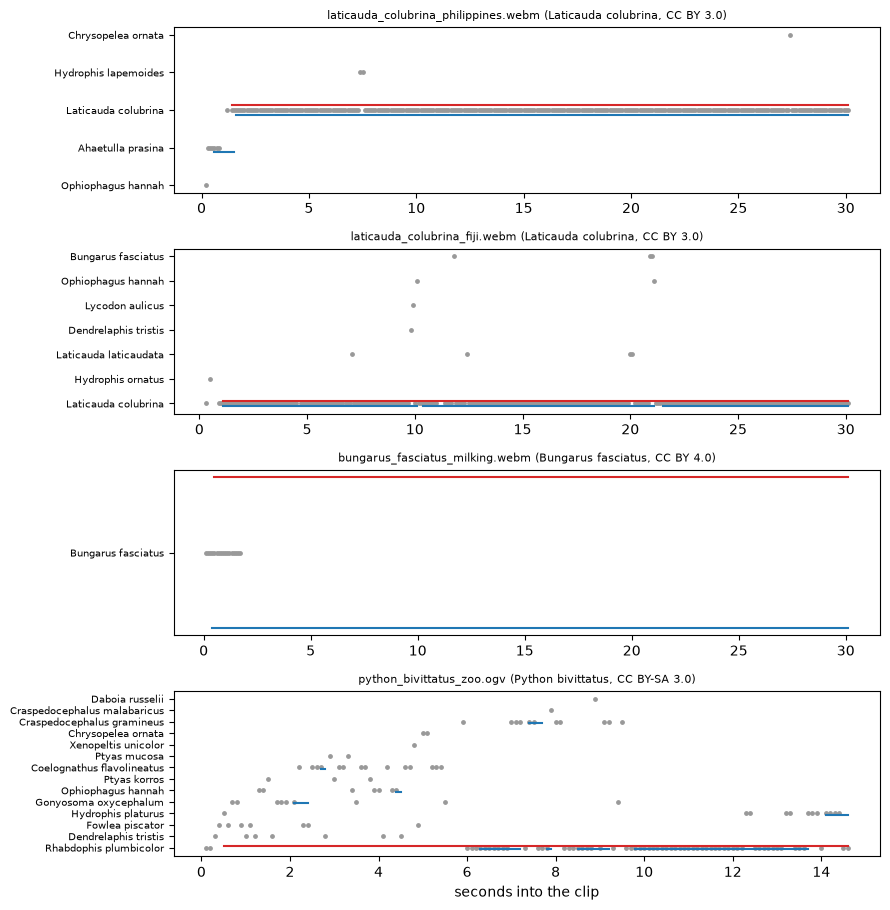

In [15]:
def show_timeline(c, ax):
    probs, times = c["probs"], c["times"]
    locked, _ = lock_run(probs, times, MARGIN, WINDOW)
    voted = vote_shown(probs)
    tops = [None if p is None else int(np.argmax(p["probs"])) for p in probs]
    seen = [s for s in dict.fromkeys(tops + voted + locked) if s is not None]
    row = {s: i for i, s in enumerate(seen)}

    def height(series, offset):
        return [np.nan if s is None else row[s] + offset for s in series]

    ax.scatter(times, height(tops, 0), color="0.6", s=6)
    ax.step(times, height(voted, -0.12), where="post", color="tab:blue", lw=1.5)
    ax.step(times, height(locked, 0.12), where="post", color="tab:red", lw=1.5)
    ax.set_yticks(range(len(seen)), [NAMES[s] for s in seen], fontsize=7)
    ax.set_title(f"{c['clip'][:48]} ({c['species']}, {c['licence']})", fontsize=8)


real = [c for c in clips if c["kind"] == "real"][:4]
fig, axes = plt.subplots(len(real), 1, figsize=(9, 2.3 * len(real)), squeeze=False)
for c, ax in zip(real, axes[:, 0]):
    show_timeline(c, ax)
axes[-1, 0].set_xlabel("seconds into the clip")
plt.tight_layout()
plt.show()

## 9. Checks

Every real clip has its licence and source url recorded; a clip with no snake should never lock; and
no result holds a missing value where one is needed.

The negative controls (`negatives.csv`) are CC clips of other things: a chameleon, an eagle and a
river seen from a drone. The lock needs the gate to call a snake on a full window of frames and then a
confident pooled species. The chameleon and the eagle should never lock under the chosen pair. On the
Milestone 3 model the river was a **detector false alarm**: the M3 detector called the winding river a
snake on about half the frames and the model then locked on it. With the no-snake gate on, the table
below shows on how many of its frames the gate still calls a snake and whether the lock engages; the
river is listed, not asserted. The line under the table says whether the chameleon and the eagle stay
unlocked.

In [16]:
assert manifest[["clip", "species", "source_url", "licence", "split"]].notna().all().all()
assert set(manifest["licence"]) <= {"CC BY 2.0", "CC BY 3.0", "CC BY 4.0", "CC BY-SA 2.0", "CC BY-SA 3.0",
                                    "CC BY-SA 4.0", "CC0", "Public domain"}
assert negatives_manifest[["clip", "source_url", "licence"]].notna().all().all()
rows = []
for name, (probs, times) in negative_clips.items():
    steps = video.pooled_lock(probs, times, CONF, MARGIN, window=WINDOW)
    verdicts = video.lock_verdicts(steps, thresholds, prototypes, tables)
    locked_species = sorted({NAMES[s["species"]] for s in steps if s["species"] is not None})
    rows.append({"clip": name, "frames": len(probs), "snake_frames": sum(p is not None for p in probs),
                 "locked_frames": sum(s["state"] == "locked" for s in steps), "locked_to": locked_species,
                 "verdicts_shown": sorted({v for v in verdicts if v})})
negatives = pd.DataFrame(rows)
display(negatives)
clean = negatives[~negatives["clip"].isin(M3_FALSE_ALARM)]
assert len(clean) >= 2
unlocked = bool((clean.locked_frames == 0).all())
print("negative control, the chameleon and the eagle never lock: "
      + ("passed" if unlocked else "FAILED, " + "; ".join(f"{r.clip} locks on {r.locked_frames} of {r.frames} frames "
                                                        f"({', '.join(r.locked_to)})" for r in clean.itertuples()
                                                        if r.locked_frames)))
river = negatives[negatives["clip"].isin(M3_FALSE_ALARM)].iloc[0]
print(f"river (the M3 detector's false alarm): the gate calls a snake on {river.snake_frames} of {river.frames} frames; "
      f"the lock {'engages on ' + str(river.locked_frames) + ' frames' if river.locked_frames else 'never engages'}")
# with no snake found at all the lock is never reached, whatever the clip length
assert all(s["state"] == "checking" for s in video.pooled_lock([None] * 40, np.arange(40) / 10, CONF, MARGIN))
missing = result.drop(columns=["window", "margin", "first_answer_s", "final_shown", "final_verdict",
                               "expected_verdict", "dangerous_missed", "final_right"]).isna().sum().sum()
unanswered_without_flag = int((result.first_answer_s.isna() & result.answered).sum())
print("empty cells in the counted columns:", int(missing), "; answered clips without a time:", unanswered_without_flag)
assert missing == 0 and unanswered_without_flag == 0
print("negative controls run:", len(negatives))

,clip,frames,snake_frames,locked_frames,locked_to,verdicts_shown
0,negative_chameleon_1915.mp4,301,294,297,[Echis carinatus],[dangerous]
1,negative_eagle_goa.ogv,189,82,147,"[Hydrophis platurus, Laticauda colubrina]",[dangerous]
2,negative_river_wyoming.webm,301,84,8,[Python bivittatus],[dangerous]


negative control, the chameleon and the eagle never lock: FAILED, negative_chameleon_1915.mp4 locks on 297 of 301 frames (Echis carinatus); negative_eagle_goa.ogv locks on 147 of 189 frames (Hydrophis platurus, Laticauda colubrina)
river (the M3 detector's false alarm): the gate calls a snake on 84 of 301 frames; the lock engages on 8 frames
empty cells in the counted columns: 0 ; answered clips without a time: 0
negative controls run: 3
